# Experiment 1
The aim of experiment 1 is to test whether the spike train, produced by 2 sensory modalities converging upon a bimodal neuron, is unique in terms of frequency. Given a sensory modalities A and B, the spike train should be able to uniquely demonstrate that currents have been injected via 2 segregated dendrites.

Hypothesis: the frequency of the spike train will differ between A or B versus A and B

In [6]:
import pygenn
import time
from Tools import EEG
import numpy
import matplotlib.pyplot as plt

In [7]:
_bimodal_LIF = pygenn.create_neuron_model(
    class_name = "bimodalLIF",
    params     = ["C", "TauM", "Vrest", "Vreset", "Vthresh", "Ioffset", "TauRefrac"],
    vars       = [
        ("V", "scalar"),
        ("RefracTime", "scalar")
    ],
    derived_params = [
        ("ExpTC", lambda pars, dt : numpy.exp(-dt / pars["TauM"])),
        ("Rmembrane", lambda pars, dt : pars["TauM"] / pars["C"])
    ],
    additional_input_vars = [
        ("IsynVisual", "scalar", 0.0),
        ("IsynSomatosensory", "scalar", 0.0),
    ],
    sim_code = """
    if (RefracTime <= 0.0) {
        const scalar alpha = ((Isyn + IsynVisual + IsynSomatosensory + Ioffset) * Rmembrane) + Vrest;
        V = alpha - (ExpTC * (alpha - V));
    } else {
        RefracTime -= dt;
    }
    """,
    threshold_condition_code = "RefracTime <= 0.0 && V >= Vthresh",
    reset_code = """
    V = Vreset;
    RefracTime = TauRefrac;
    """
)

In [8]:
model = pygenn.GeNNModel(
    precision       = "float",
    model_name      = "experiment1Model"
)

sensModality1Pop = model.add_neuron_population(
    pop_name    = "sensModality1Pop",
    num_neurons = 1,
    neuron      = "LIF",
    params      = {
        "C"         : 2.0,
        "TauM"      : 20.0,
        "Vrest"     : -60.0,
        "Vthresh"   : -50.0,
        "Ioffset"   : 0.0,
        "TauRefrac" : 2.0,
        "Vreset"    : -60.0
    },
    vars        = {
        "V"          : -60.0,
        "RefracTime" : 0.0
    }
)
sensModality2Pop = model.add_neuron_population(
    pop_name    = "sensModality2Pop",
    num_neurons = 1,
    neuron      = "LIF",
    params      = {
        "C"         : 2.0,
        "TauM"      : 20.0,
        "Vrest"     : -60.0,
        "Vthresh"   : -50.0,
        "Ioffset"   : 0.0,
        "TauRefrac" : 2.0,
        "Vreset"    : -60.0
    },
    vars        = {
        "V"          : -60.0,
        "RefracTime" : 0.0
    }
)
convergentPop = model.add_neuron_population(
    pop_name    = "convergentPop",
    num_neurons = 1,
    neuron      = _bimodal_LIF,
    params      = {
        "C"         : 0.25,
        "TauM"      : 20.0,
        "Vrest"     : -60.0,
        "Vreset"    : -60.0,
        "Vthresh"   : -50.0,
        "Ioffset"   : 0.0,
        "TauRefrac" : 2.0,
    },
    vars        = {
        "V"          : -60.0,
        "RefracTime" : 0.0
    }
)

stimulus1 = model.add_current_source(
    cs_name              = "stimulus1",
    current_source_model = "DC",
    pop                  = sensModality1Pop,
    params               = {
        "amp" : 0.0
    }
)
stimulus2 = model.add_current_source(
    cs_name              = "stimulus2",
    current_source_model = "DC",
    pop                  = sensModality2Pop,
    params               = {
        "amp" : 0.0
    }
)
stimulus1.set_param_dynamic("amp")
stimulus2.set_param_dynamic("amp")

mod1ToConvergentSynapsePop = model.add_synapse_population(
    pop_name           = "mod1ToConvergentSynapsePop",
    matrix_type        = "DENSE",
    source             = sensModality1Pop,
    target             = convergentPop,
    weight_update_init = pygenn.init_weight_update(
        "StaticPulseConstantWeight",
        {"g" : 0.5}
    ),
    postsynaptic_init  = pygenn.init_postsynaptic(
        "ExpCurr",
        {"tau" : 5.0}
    )
)
mod1ToConvergentSynapsePop.post_target_var = "IsynVisual"
mod2ToConvergentSynapsePop = model.add_synapse_population(
    pop_name           = "mod2ToConvergentSynapsePop",
    matrix_type        = "DENSE",
    source             = sensModality2Pop,
    target             = convergentPop,
    weight_update_init = pygenn.init_weight_update(
        "StaticPulseConstantWeight",
        {"g" : 0.5}
    ),
    postsynaptic_init  = pygenn.init_postsynaptic(
        "ExpCurr",
        {"tau" : 5.0}
    )
)
mod2ToConvergentSynapsePop.post_target_var = "IsynSomatosensory"

for pop in (sensModality1Pop, sensModality2Pop, convergentPop):
    pop.spike_recording_enabled = True

model.build()

In [9]:
injectionPeriodicity = 5.0 * 1000.0    # 5s
injectionDuration    = 0.5 * 1000.0    # 0.5s
injectionCurrent     = 2.0
simTime              = 60.0 * 1000.0   # 60 s

schedule = [
    ("visual", (1, 0)),
    ("somatosensory", (0, 1)),
    ("both", (1, 1))
]

simSteps = int(round(simTime / model.dt))
model.load(num_recording_timesteps=simSteps)

eeg = EEG({
    "visual"              : (sensModality1Pop, [0]),
    "somatosensory"       : (sensModality2Pop, [0]),
    "convergentPop"       : (convergentPop, [0]),
})

injections     = []  # (condition, start time)
injecting      = False
nextInjection  = 0.0
injectionIndex = 0

while model.t < simTime:
    if not injecting and model.t >= nextInjection:
        condition, (c1, c2) = schedule[injectionIndex % len(schedule)]
        stimulus1.set_dynamic_param_value("amp", injectionCurrent * c1)
        stimulus2.set_dynamic_param_value("amp", injectionCurrent * c2)
        injections.append((condition, model.t))
        injecting = True
        injectionIndex += 1
    elif injecting and model.t >= injections[-1][1] + injectionDuration:
        stimulus1.set_dynamic_param_value("amp", 0.0)
        stimulus2.set_dynamic_param_value("amp", 0.0)
        injecting = False
        nextInjection = injections[-1][1] + injectionPeriodicity

    model.step_time()
    eeg.log(model.t)

model.pull_recording_buffers_from_device()
targetTimes, _ = convergentPop.spike_recording_data[0]


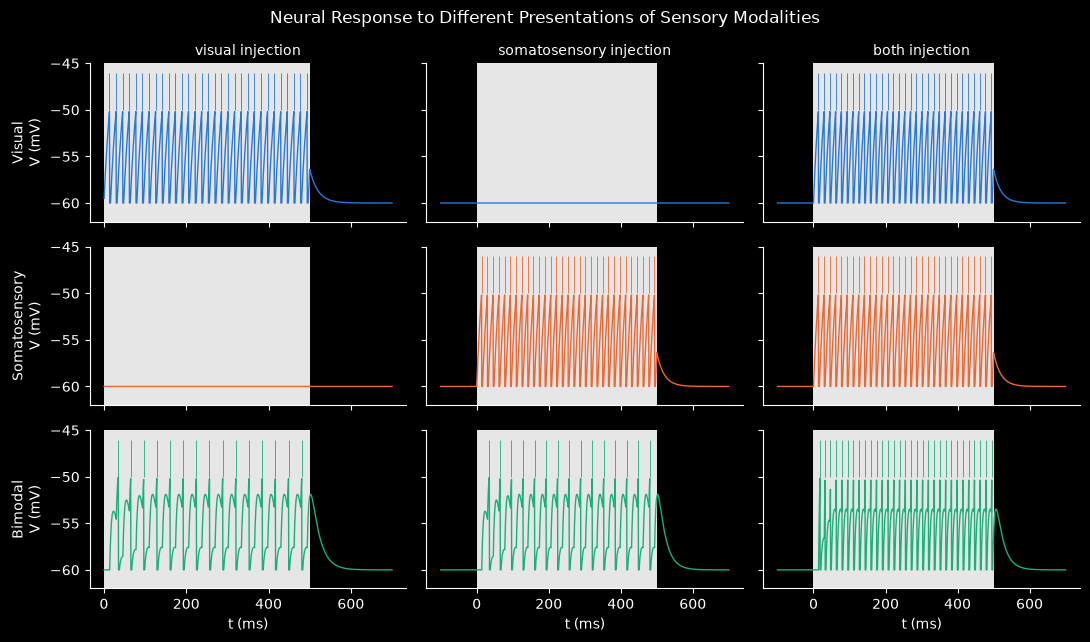

In [19]:
traces = [("visual", sensModality1Pop, "Visual", "#2a78d6"),
          ("somatosensory", sensModality2Pop, "Somatosensory", "#eb6834"),
          ("convergentPop", convergentPop, "Bimodal", "#1baf7a")]
firstOfEach = {}
for condition, t0 in injections:
    firstOfEach.setdefault(condition, t0)

pre, post = 100.0, 200.0    # ms shown before / after each injection
fig, axes = plt.subplots(len(traces), len(firstOfEach), sharex="col",
                         sharey=True, figsize=(11, 6.5), squeeze=False)

for col, (condition, t0) in enumerate(firstOfEach.items()):
    axes[0, col].set_title(f"{condition} injection", fontsize=10)
    for row, (popName, pop, label, colour) in enumerate(traces):
        ax = axes[row, col]
        t, V = eeg.getTrace(popName, 0)
        keep = (t >= t0 - pre) & (t <= t0 + injectionDuration + post)
        ax.plot(t[keep] - t0, V[keep], color=colour, linewidth=1.0)

        # The LIF resets within the step it crosses threshold, so V never
        # shows the spike itself: mark spike times as ticks above threshold.
        spikeTimes, _ = pop.spike_recording_data[0]
        spikeTimes = spikeTimes[(spikeTimes >= t0 - pre)
                                & (spikeTimes <= t0 + injectionDuration + post)]
        ax.vlines(spikeTimes - t0, -50.0, -46.0, color=colour, linewidth=0.6)

        ax.axvspan(0.0, injectionDuration, color="0.9", zorder=0, linewidth=0)
        ax.set_ylim(-62.0, -45.0)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        if col == 0:
            ax.set_ylabel(f"{label}\nV (mV)")
    axes[-1, col].set_xlabel("t (ms)")

plt.suptitle("Neural Response to Different Presentations of Sensory Modalities")
fig.tight_layout()
plt.show()


population                 baseline              visual       somatosensory                both             overall
-------------------------------------------------------------------------------------------------------------------
Visual                0.00 ± 0.00  Hz      62.00 ± 0.00  Hz       0.00 ± 0.00  Hz      62.00 ± 0.00  Hz       4.13 ± 0.00  Hz
Somatosensory         0.00 ± 0.00  Hz       0.00 ± 0.00  Hz      62.00 ± 0.00  Hz      62.00 ± 0.00  Hz       4.13 ± 0.00  Hz
Bimodal               0.00 ± 0.00  Hz      30.00 ± 0.00  Hz      30.00 ± 0.00  Hz      62.00 ± 0.00  Hz       4.07 ± 0.00  Hz


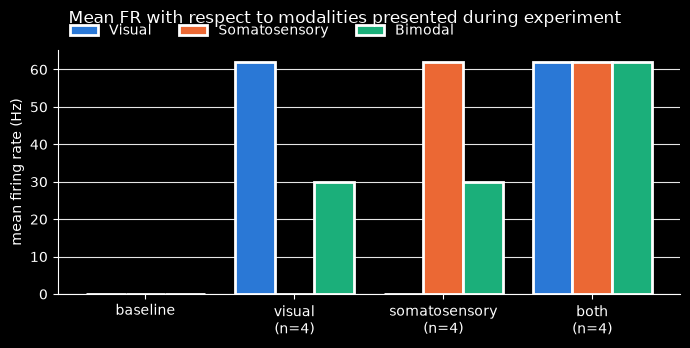

In [20]:
fig.tight_layout()

# ---------------------------------------------------------------------------
# Mean firing rates
# ---------------------------------------------------------------------------
def windowSpikeCounts(spikeTimes, starts, ends):
    """Spikes (summed over neurons) in each half-open window [start, end).

    spikeTimes must be sorted; GeNN returns them in timestep order.
    """
    return (numpy.searchsorted(spikeTimes, ends, side="left")
            - numpy.searchsorted(spikeTimes, starts, side="left"))

injStarts     = numpy.array([t0 for _, t0 in injections])
injConditions = numpy.array([condition for condition, _ in injections])
injEnds       = numpy.minimum(injStarts + injectionDuration, simTime)  # clip a window cut off by the end of the run
injWidths     = injEnds - injStarts
conditions    = ["baseline"] + [name for name, _ in schedule]

rates = {}   # label -> {condition -> per-trial rates (Hz)}
for popName, pop, label, colour in traces:
    spikeTimes, _ = pop.spike_recording_data[0]
    N = pop.num_neurons

    counts     = windowSpikeCounts(spikeTimes, injStarts, injEnds)
    trialRates = 1000.0 * counts / (N * injWidths)                 # ms -> s

    rates[label] = {name: trialRates[injConditions == name] for name, _ in schedule}
    rates[label]["baseline"] = numpy.array(
        [1000.0 * (len(spikeTimes) - counts.sum()) / (N * (simTime - injWidths.sum()))])
    rates[label]["overall"] = numpy.array([1000.0 * len(spikeTimes) / (N * simTime)])

def meanSD(r):
    return r.mean(), (r.std(ddof=1) if len(r) > 1 else 0.0)

header = f"{'population':<15}" + "".join(f"{c:>20}" for c in conditions + ["overall"])
print(header)
print("-" * len(header))
for label, byCondition in rates.items():
    row = f"{label:<15}"
    for c in conditions + ["overall"]:
        m, s = meanSD(byCondition[c])
        row += f"{m:>11.2f} ± {s:<5.2f} Hz"
    print(row)

# Grouped bars: condition on x, one bar per population (same colours as the trace figure)
figRates, axRates = plt.subplots(figsize=(7.0, 3.5))
barWidth = 0.8 / len(traces)
x = numpy.arange(len(conditions))
for i, (_, _, label, colour) in enumerate(traces):
    stats = numpy.array([meanSD(rates[label][c]) for c in conditions])
    axRates.bar(x + (i - (len(traces) - 1) / 2) * barWidth, stats[:, 0], width=barWidth,
                yerr=stats[:, 1] if stats[:, 1].any() else None,   # SD is 0 while the model is noise-free
                capsize=2, color=colour, edgecolor="white",
                linewidth=2, label=label, error_kw={"elinewidth": 1})
axRates.set_xticks(x, [f"{c}\n(n={len(rates[traces[0][2]][c])})" if c != "baseline" else c
                       for c in conditions])
axRates.set_ylabel("mean firing rate (Hz)")
axRates.yaxis.grid(True, color="0.9", linewidth=0.8)
axRates.set_axisbelow(True)
for side in ("top", "right"):
    axRates.spines[side].set_visible(False)
axRates.legend(frameon=False, ncols=len(traces), loc="lower left", bbox_to_anchor=(0.0, 1.0))
figRates.tight_layout()

plt.suptitle("Mean FR with respect to modalities presented during experiment")
plt.show()

In [ ]:
b